# COMP472 Project – Neural Network

In this notebook we train a **feed-forward neural network (MLP)** with PyTorch on both tasks:

* **Image** – 50 classes, 500 features per image
* **Sentiment** – 3 classes (Negative / Neutral / Positive), 768 features per text

Plan of the notebook

1. Load the data
2. Split into train / validation and preprocess
3. Define the network
4. Write the training loop
5. Sentiment: baseline + experiments (change one hyperparameter at a time)
6. Image: baseline + experiments
7. Best models: several seeds, confusion matrix, error analysis
8. Final models: train on all the data, predict the test set, write the Kaggle file

`common.py` (in the project root folder) holds the code the whole team shares: loading the CSVs, the 80/20 split and the metrics.

**Running time on a laptop CPU:** sections 1–5 about 10–15 min, section 6 about 20–30 min.

## 0. Imports and settings

In [1]:
import os
import sys

# This notebook is in a sub-folder. Work from the project root: the folder
# that contains common.py, Project_info/, results/ and predictions/.
if not os.path.exists("common.py"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import os
import time
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

import common   # our shared file

common.set_seed(42)

# Use the GPU if there is one, otherwise the CPU (both work)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| running on", device)

# Folders for the results
os.makedirs("results/nn", exist_ok=True)
os.makedirs("predictions", exist_ok=True)

PyTorch 2.15.0+cpu | running on cpu


## 1. Load the data

In [2]:
X_image, y_image, X_image_test, image_test_ids = common.load_task("image")
X_sent, y_sent, X_sent_test, sent_test_ids = common.load_task("sentiment")

print("Image     train:", X_image.shape, " test:", X_image_test.shape)
print("Sentiment train:", X_sent.shape, " test:", X_sent_test.shape)
print("Examples per image class:", np.bincount(y_image)[:5], "...")
print("Examples per sentiment class:", np.bincount(y_sent))

Image     train: (20000, 500)  test: (5000, 500)
Sentiment train: (12000, 768)  test: (5000, 768)
Examples per image class: [400 400 400 400 400] ...
Examples per sentiment class: [4000 4000 4000]


## 2. Train / validation split and preprocessing

* We keep **20% of the training data as a validation set**. All model choices are made with it (not with the Kaggle leaderboard).
* The split is **stratified** (every class keeps 80% / 20%) and always uses seed 42, so every model in the team is compared on the same rows.
* Preprocessing statistics (mean, std) are computed **on the training part only**, so no information from the validation set leaks into training.

Preprocessing options (see `common.py`):

| mode | what it does | used for |
|---|---|---|
| `"none"` | nothing | – |
| `"standardize"` | (x − mean) / std for every feature | sentiment (BERT features have very different scales) |
| `"sqrt"` | √x, then each row scaled to length 1 | image (features are ≥ 0 and 85% zeros, like a histogram) |
| `"sqrt_standardize"` | both | – |

In [3]:
def prepare(X, y, mode):
    # 1) split the row numbers 80 / 20
    train_idx, val_idx = common.stratified_split(y)
    # 2) learn mean / std from the TRAINING rows only
    stats = common.fit_preprocessing(X[train_idx], mode)
    # 3) apply the same transformation to train and validation
    X_train = common.apply_preprocessing(X[train_idx], mode, stats)
    X_val = common.apply_preprocessing(X[val_idx], mode, stats)
    return X_train, y[train_idx], X_val, y[val_idx]


X_tr, y_tr, X_va, y_va = prepare(X_sent, y_sent, "standardize")
print("train:", X_tr.shape, " validation:", X_va.shape)
print("validation examples per class:", np.bincount(y_va))

train: (9600, 768)  validation: (2400, 768)
validation examples per class: [800 800 800]


## 3. The network

An MLP is a stack of layers:

```
input → [Linear → activation → Dropout] → [Linear → activation → Dropout] → ... → Linear → output
```

* `hidden_sizes = [256, 64]` means two hidden layers with 256 and 64 neurons.
* `hidden_sizes = []` means no hidden layer at all: input → output. That is a **linear model** (softmax regression); useful to see whether hidden layers help.
* The output layer has one neuron per class (50 for image, 3 for sentiment). It outputs raw scores; the class with the highest score is the prediction.
* **Dropout** randomly turns off some neurons during training, so the network cannot rely too much on any single one (reduces overfitting).
* **Input dropout** does the same to the input features. For the image features this is like showing slightly incomplete images.

In [4]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_outputs, hidden_sizes, activation="relu",
                 dropout=0.0, input_dropout=0.0):
        super().__init__()
        layers = []

        if input_dropout > 0:
            layers.append(nn.Dropout(input_dropout))

        size_in = n_inputs
        for size_out in hidden_sizes:
            layers.append(nn.Linear(size_in, size_out))
            if activation == "relu":
                layers.append(nn.ReLU())
            elif activation == "tanh":
                layers.append(nn.Tanh())
            elif activation == "sigmoid":
                layers.append(nn.Sigmoid())
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            size_in = size_out

        layers.append(nn.Linear(size_in, n_outputs))   # output layer
        self.layers = nn.Sequential(*layers)

    def forward(self, x):
        return self.layers(x)


# Example: the network from the project description
example = MLP(n_inputs=500, n_outputs=50, hidden_sizes=[256, 64])
print(example)
print("number of weights:", sum(p.numel() for p in example.parameters()))

MLP(
  (layers): Sequential(
    (0): Linear(in_features=500, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=50, bias=True)
  )
)
number of weights: 147954


## 4. Training

One **epoch** = the network sees every training example once. For each small group of examples (a **batch**):

1. **forward pass** – the network makes predictions
2. **loss** – cross-entropy measures how wrong the predictions are
3. **backward pass** – PyTorch computes the gradient of the loss for every weight
4. **optimizer step** – every weight moves a little in the direction that lowers the loss

After each epoch we measure the accuracy on the validation set.

**Early stopping:** if the validation accuracy has not improved for `patience` epochs, we stop and go back to the weights of the best epoch. This prevents training for too long (overfitting).

All the hyperparameters are kept in one dictionary called `settings`. `DEFAULT_SETTINGS` gives a value to every one of them; an experiment only changes the ones it lists.

In [5]:
DEFAULT_SETTINGS = {
    "preprocess": "standardize",
    "hidden_sizes": [256],
    "activation": "relu",
    "dropout": 0.0,
    "input_dropout": 0.0,
    "optimizer": "adam",
    "lr": 1e-3,              # learning rate
    "weight_decay": 0.0,     # L2 penalty on the weights
    "batch_size": 128,
    "max_epochs": 100,
    "patience": 10,          # early stopping
}


def get_accuracy_and_loss(model, X, y, loss_function):
    model.eval()                       # evaluation mode: dropout is turned off
    with torch.no_grad():              # no gradients needed here
        outputs = model(X)
        loss = loss_function(outputs, y).item()
        predictions = outputs.argmax(dim=1)
        accuracy = (predictions == y).float().mean().item()
    return accuracy, loss


def train(X_train, y_train, X_val, y_val, n_classes, settings, seed=42, verbose=False):
    s = dict(DEFAULT_SETTINGS)         # start from the defaults ...
    s.update(settings)                 # ... and overwrite with the given settings
    common.set_seed(seed)

    # NumPy arrays -> PyTorch tensors
    X_train = torch.tensor(X_train).to(device)
    y_train = torch.tensor(y_train).to(device)
    X_val = torch.tensor(X_val).to(device)
    y_val = torch.tensor(y_val).to(device)

    model = MLP(X_train.shape[1], n_classes, s["hidden_sizes"], s["activation"],
                s["dropout"], s["input_dropout"]).to(device)
    loss_function = nn.CrossEntropyLoss()

    if s["optimizer"] == "adam":
        optimizer = torch.optim.AdamW(model.parameters(), lr=s["lr"], weight_decay=s["weight_decay"])
    else:
        optimizer = torch.optim.SGD(model.parameters(), lr=s["lr"], momentum=0.9,
                                    weight_decay=s["weight_decay"])

    history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}
    best_val_acc = 0.0
    best_epoch = 0
    best_weights = None
    epochs_without_improvement = 0

    for epoch in range(1, s["max_epochs"] + 1):
        # ---- training: go through the data in random batches ----
        model.train()                                  # dropout is turned on
        order = torch.randperm(len(X_train), device=device)   # new random order every epoch
        for start in range(0, len(X_train), s["batch_size"]):
            batch = order[start:start + s["batch_size"]]
            outputs = model(X_train[batch])                  # 1. forward pass
            loss = loss_function(outputs, y_train[batch])    # 2. loss
            optimizer.zero_grad()
            loss.backward()                                  # 3. backward pass
            optimizer.step()                                 # 4. update the weights

        # ---- measure after this epoch ----
        train_acc, train_loss = get_accuracy_and_loss(model, X_train, y_train, loss_function)
        val_acc, val_loss = get_accuracy_and_loss(model, X_val, y_val, loss_function)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        if verbose:
            print(f"epoch {epoch:3d}   train acc {train_acc:.3f}   val acc {val_acc:.3f}")

        # ---- early stopping ----
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch
            best_weights = copy.deepcopy(model.state_dict())   # save a copy of the weights
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
        if epochs_without_improvement >= s["patience"]:
            break

    model.load_state_dict(best_weights)       # go back to the best epoch
    history["best_epoch"] = best_epoch
    return model, history


def plot_history(history, title):
    epochs = range(1, len(history["train_acc"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(epochs, history["train_loss"], label="train")
    ax1.plot(epochs, history["val_loss"], label="validation")
    ax1.set_title("Loss")
    ax1.set_xlabel("epoch")
    ax2.plot(epochs, history["train_acc"], label="train")
    ax2.plot(epochs, history["val_acc"], label="validation")
    ax2.axvline(history["best_epoch"], color="gray", linestyle="--", label="best epoch")
    ax2.set_title("Accuracy")
    ax2.set_xlabel("epoch")
    for ax in (ax1, ax2):
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

### Helper for experiments

`run_experiment` trains one network for each value of one hyperparameter. Everything else stays at the baseline, so any change in accuracy comes from that hyperparameter only.

For each run we record:

* **train acc / val acc** at the best epoch
* **gap** = train acc − val acc (a big gap means overfitting)
* **best epoch** – how many epochs were useful
* **seconds** – training time

In [6]:
all_results = []   # every run of every experiment ends up here


def run_experiment(task, X, y, n_classes, baseline, name, values):
    rows = []
    for value in values:
        settings = dict(baseline)          # copy the baseline
        settings[name] = value             # change ONE hyperparameter

        X_tr, y_tr, X_va, y_va = prepare(X, y, settings["preprocess"])
        start = time.time()
        model, history = train(X_tr, y_tr, X_va, y_va, n_classes, settings)
        seconds = time.time() - start

        best = history["best_epoch"] - 1   # list index of the best epoch
        row = {
            "task": task,
            "hyperparameter": name,
            "value": str(value),
            "train_acc": round(history["train_acc"][best], 4),
            "val_acc": round(history["val_acc"][best], 4),
            "gap": round(history["train_acc"][best] - history["val_acc"][best], 4),
            "best_epoch": history["best_epoch"],
            "seconds": round(seconds, 1),
        }
        rows.append(row)
        all_results.append(row)
        print(f"{name} = {str(value):<16} val {row['val_acc']:.4f}   train {row['train_acc']:.4f}"
              f"   gap {row['gap']:+.3f}   best epoch {row['best_epoch']:3d}   {row['seconds']}s")

    table = pd.DataFrame(rows)
    plot_experiment(table, f"{task}: {name}")
    return table


def plot_experiment(table, title):
    x = np.arange(len(table))
    plt.figure(figsize=(7, 3.5))
    plt.bar(x - 0.2, table["train_acc"], width=0.4, label="train")
    plt.bar(x + 0.2, table["val_acc"], width=0.4, label="validation")
    plt.xticks(x, table["value"], rotation=20)
    plt.ylim(0, 1)
    plt.ylabel("accuracy")
    plt.title(title)
    plt.legend()
    plt.grid(axis="y", alpha=0.3)
    plt.show()

## 5. Sentiment

### 5.1 Baseline

Starting point, found in a first exploration: one hidden layer of 512 neurons, dropout 0.5, a small learning rate (1e-4) for smooth training, and weight decay 0.01.

best epoch: 27 | validation accuracy: 0.6808


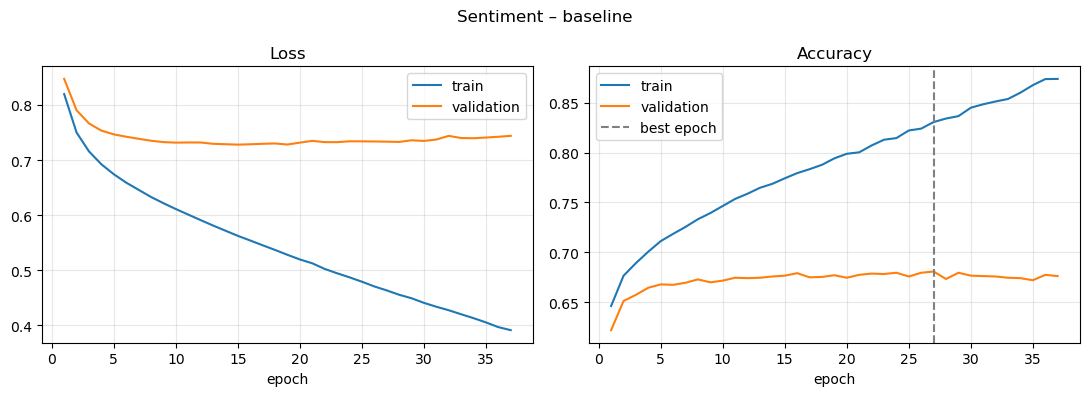

In [7]:
SENTIMENT_BASELINE = {
    "preprocess": "standardize",
    "hidden_sizes": [512],
    "dropout": 0.5,
    "input_dropout": 0.2,
    "lr": 1e-4,
    "weight_decay": 1e-2,
}

X_tr, y_tr, X_va, y_va = prepare(X_sent, y_sent, SENTIMENT_BASELINE["preprocess"])
model, history = train(X_tr, y_tr, X_va, y_va, 3, SENTIMENT_BASELINE)
print("best epoch:", history["best_epoch"],
      "| validation accuracy:", round(history["val_acc"][history["best_epoch"] - 1], 4))
plot_history(history, "Sentiment – baseline")

### 5.2 Experiments (one hyperparameter at a time)

preprocess = none             val 0.6867   train 0.7347   gap +0.048   best epoch  47   132.2s
preprocess = standardize      val 0.6808   train 0.8305   gap +0.150   best epoch  27   79.4s


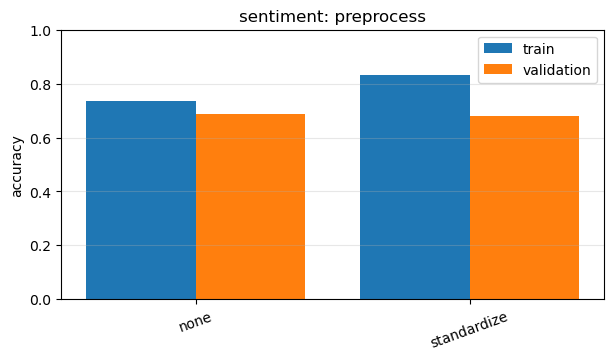

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,sentiment,preprocess,none,0.7347,0.6867,0.0480,47,132.2
1,sentiment,preprocess,standardize,0.8305,0.6808,0.1497,27,79.4


In [8]:
# Preprocessing
run_experiment("sentiment", X_sent, y_sent, 3, SENTIMENT_BASELINE,
               "preprocess", ["none", "standardize"])

hidden_sizes = []               val 0.6708   train 0.6856   gap +0.015   best epoch  12   18.2s
hidden_sizes = [64]             val 0.6783   train 0.7237   gap +0.045   best epoch  20   36.0s
hidden_sizes = [256]            val 0.6812   train 0.7502   gap +0.069   best epoch  15   37.6s
hidden_sizes = [512]            val 0.6808   train 0.8305   gap +0.150   best epoch  27   77.9s
hidden_sizes = [256, 64]        val 0.6825   train 0.7385   gap +0.056   best epoch  17   49.1s
hidden_sizes = [512, 256, 128]  val 0.6808   train 0.7861   gap +0.105   best epoch  21   98.0s


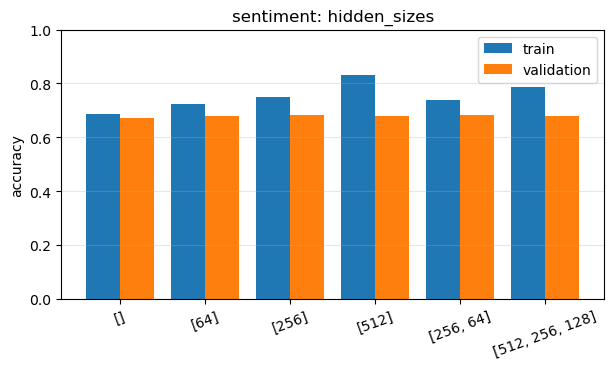

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,sentiment,hidden_sizes,[],0.6856,0.6708,0.0148,12,18.2
1,sentiment,hidden_sizes,[64],0.7237,0.6783,0.0454,20,36.0
2,sentiment,hidden_sizes,[256],0.7502,0.6812,0.0690,15,37.6
3,sentiment,hidden_sizes,[512],0.8305,0.6808,0.1497,27,77.9
4,sentiment,hidden_sizes,"[256, 64]",0.7385,0.6825,0.0560,17,49.1
5,sentiment,hidden_sizes,"[512, 256, 128]",0.7861,0.6808,0.1053,21,98.0


In [9]:
# Number of hidden layers and their size ([] = no hidden layer = linear model)
run_experiment("sentiment", X_sent, y_sent, 3, SENTIMENT_BASELINE,
               "hidden_sizes", [[], [64], [256], [512], [256, 64], [512, 256, 128]])

activation = relu             val 0.6808   train 0.8305   gap +0.150   best epoch  27   72.8s
activation = tanh             val 0.6775   train 0.7265   gap +0.049   best epoch  16   13.8s
activation = sigmoid          val 0.6767   train 0.7015   gap +0.025   best epoch  17   14.7s


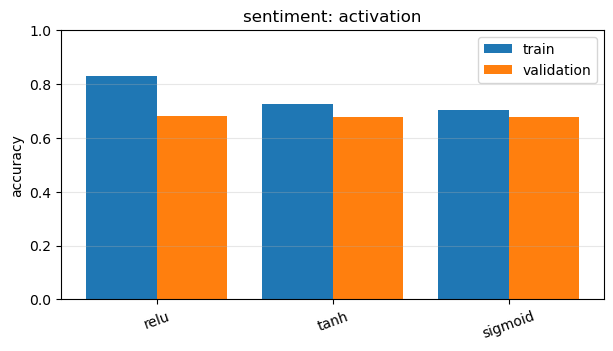

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,sentiment,activation,relu,0.8305,0.6808,0.1497,27,72.8
1,sentiment,activation,tanh,0.7265,0.6775,0.0490,16,13.8
2,sentiment,activation,sigmoid,0.7015,0.6767,0.0248,17,14.7


In [10]:
# Activation function
run_experiment("sentiment", X_sent, y_sent, 3, SENTIMENT_BASELINE,
               "activation", ["relu", "tanh", "sigmoid"])

dropout = 0.0              val 0.6800   train 0.7409   gap +0.061   best epoch   6   11.7s
dropout = 0.2              val 0.6804   train 0.7702   gap +0.090   best epoch  10   23.1s
dropout = 0.5              val 0.6808   train 0.8305   gap +0.150   best epoch  27   53.3s
dropout = 0.7              val 0.6783   train 0.7462   gap +0.068   best epoch  15   51.3s


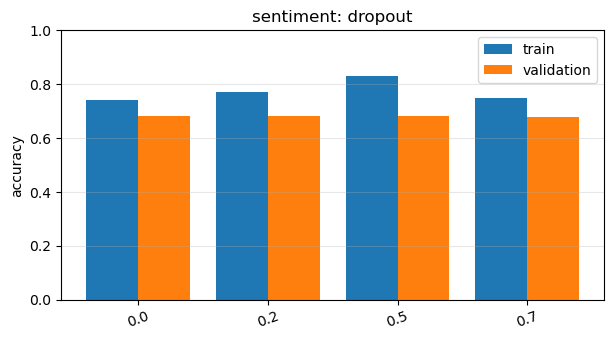

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,sentiment,dropout,0.0,0.7409,0.6800,0.0609,6,11.7
1,sentiment,dropout,0.2,0.7702,0.6804,0.0898,10,23.1
2,sentiment,dropout,0.5,0.8305,0.6808,0.1497,27,53.3
3,sentiment,dropout,0.7,0.7462,0.6783,0.0679,15,51.3


In [11]:
# Dropout
run_experiment("sentiment", X_sent, y_sent, 3, SENTIMENT_BASELINE,
               "dropout", [0.0, 0.2, 0.5, 0.7])

lr = 0.01             val 0.6375   train 0.7515   gap +0.114   best epoch  21   50.0s
lr = 0.001            val 0.6708   train 0.7467   gap +0.076   best epoch   3   34.7s
lr = 0.0001           val 0.6808   train 0.8305   gap +0.150   best epoch  27   75.4s


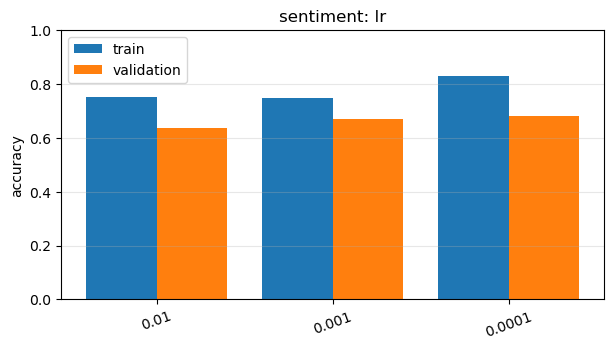

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,sentiment,lr,0.01,0.7515,0.6375,0.1140,21,50.0
1,sentiment,lr,0.001,0.7467,0.6708,0.0758,3,34.7
2,sentiment,lr,0.0001,0.8305,0.6808,0.1497,27,75.4


In [12]:
# Learning rate
run_experiment("sentiment", X_sent, y_sent, 3, SENTIMENT_BASELINE,
               "lr", [1e-2, 1e-3, 1e-4])

weight_decay = 0.0              val 0.6796   train 0.8144   gap +0.135   best epoch  24   73.9s
weight_decay = 0.001            val 0.6800   train 0.8141   gap +0.134   best epoch  24   47.6s
weight_decay = 0.01             val 0.6808   train 0.8305   gap +0.150   best epoch  27   90.0s
weight_decay = 0.1              val 0.6808   train 0.8300   gap +0.149   best epoch  27   98.2s


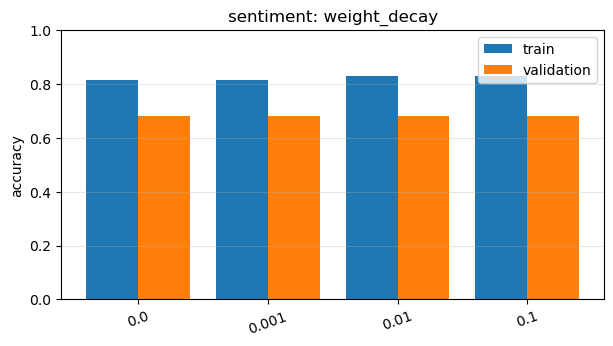

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,sentiment,weight_decay,0.0,0.8144,0.6796,0.1348,24,73.9
1,sentiment,weight_decay,0.001,0.8141,0.6800,0.1341,24,47.6
2,sentiment,weight_decay,0.01,0.8305,0.6808,0.1497,27,90.0
3,sentiment,weight_decay,0.1,0.8300,0.6808,0.1492,27,98.2


In [13]:
# Weight decay
run_experiment("sentiment", X_sent, y_sent, 3, SENTIMENT_BASELINE,
               "weight_decay", [0.0, 1e-3, 1e-2, 1e-1])

batch_size = 32               val 0.6808   train 0.7158   gap +0.035   best epoch   3   59.1s
batch_size = 128              val 0.6808   train 0.8305   gap +0.150   best epoch  27   77.7s
batch_size = 512              val 0.6787   train 0.7456   gap +0.067   best epoch  20   34.1s


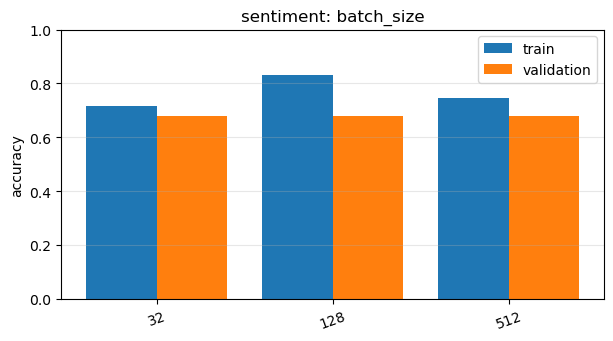

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,sentiment,batch_size,32,0.7158,0.6808,0.0350,3,59.1
1,sentiment,batch_size,128,0.8305,0.6808,0.1497,27,77.7
2,sentiment,batch_size,512,0.7456,0.6787,0.0669,20,34.1


In [14]:
# Batch size
run_experiment("sentiment", X_sent, y_sent, 3, SENTIMENT_BASELINE,
               "batch_size", [32, 128, 512])

Adam (baseline):
optimizer = adam             val 0.6808   train 0.8305   gap +0.150   best epoch  27   69.5s


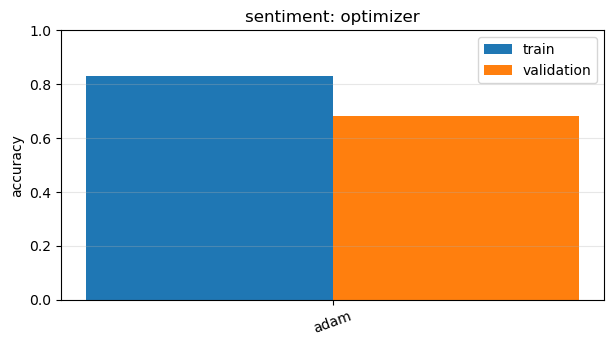

SGD with momentum:
optimizer = sgd              val 0.6796   train 0.7803   gap +0.101   best epoch   7   13.0s


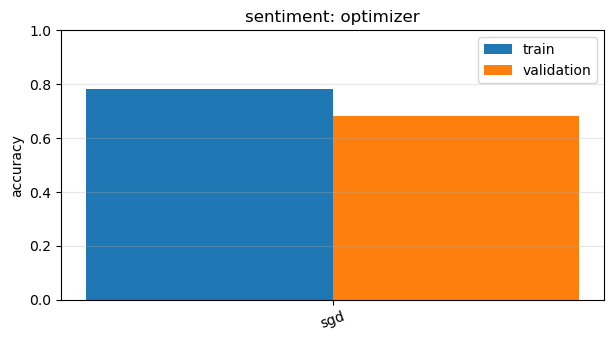

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,sentiment,optimizer,sgd,0.7803,0.6796,0.1007,7,13.0


In [15]:
# Optimizer: SGD needs a bigger learning rate than Adam, so we give it 0.01
sgd_settings = dict(SENTIMENT_BASELINE)
sgd_settings["lr"] = 1e-2
print("Adam (baseline):")
run_experiment("sentiment", X_sent, y_sent, 3, SENTIMENT_BASELINE, "optimizer", ["adam"])
print("SGD with momentum:")
run_experiment("sentiment", X_sent, y_sent, 3, sgd_settings, "optimizer", ["sgd"])

In [16]:
# Save the table of all sentiment runs
sentiment_table = pd.DataFrame([r for r in all_results if r["task"] == "sentiment"])
sentiment_table.to_csv("results/nn/sentiment_experiments.csv", index=False)
sentiment_table

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,sentiment,preprocess,none,0.7347,0.6867,0.0480,47,132.2
1,sentiment,preprocess,standardize,0.8305,0.6808,0.1497,27,79.4
2,sentiment,hidden_sizes,[],0.6856,0.6708,0.0148,12,18.2
3,sentiment,hidden_sizes,[64],0.7237,0.6783,0.0454,20,36.0
4,sentiment,hidden_sizes,[256],0.7502,0.6812,0.0690,15,37.6
5,sentiment,hidden_sizes,[512],0.8305,0.6808,0.1497,27,77.9
6,sentiment,hidden_sizes,"[256, 64]",0.7385,0.6825,0.0560,17,49.1
7,sentiment,hidden_sizes,"[512, 256, 128]",0.7861,0.6808,0.1053,21,98.0
8,sentiment,activation,relu,0.8305,0.6808,0.1497,27,72.8
9,sentiment,activation,tanh,0.7265,0.6775,0.0490,16,13.8


## 6. Image

### 6.1 Baseline

From our first exploration on the image features:

* Without any regularisation the network reaches **100% train accuracy but only about 35% validation** → strong overfitting.
* `"sqrt"` preprocessing works better than standardising (the features are sparse and ≥ 0).
* Strong regularisation helps: input dropout 0.5, dropout 0.5, weight decay 0.01 → about 42%.
* For comparison, k-NN gets about 58% on the same validation set.

best epoch: 47 | validation accuracy: 0.4283


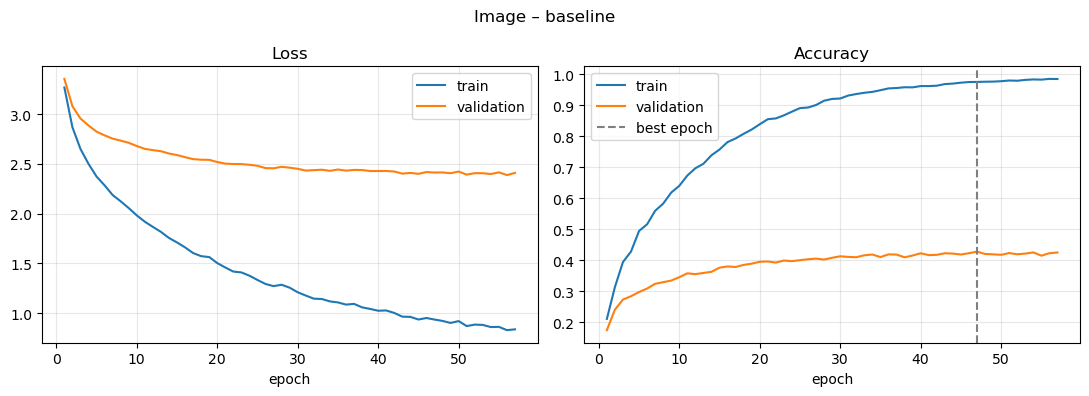

In [17]:
IMAGE_BASELINE = {
    "preprocess": "sqrt",
    "hidden_sizes": [1024],
    "dropout": 0.5,
    "input_dropout": 0.5,
    "lr": 3e-3,
    "weight_decay": 1e-2,
}

X_tr, y_tr, X_va, y_va = prepare(X_image, y_image, IMAGE_BASELINE["preprocess"])
model, history = train(X_tr, y_tr, X_va, y_va, 50, IMAGE_BASELINE)
print("best epoch:", history["best_epoch"],
      "| validation accuracy:", round(history["val_acc"][history["best_epoch"] - 1], 4))
plot_history(history, "Image – baseline")

### 6.2 Experiments (one hyperparameter at a time)

preprocess = none             val 0.4433   train 0.9834   gap +0.540   best epoch  54   275.1s
preprocess = standardize      val 0.3510   train 0.8820   gap +0.531   best epoch  37   239.3s
preprocess = sqrt             val 0.4283   train 0.9757   gap +0.547   best epoch  47   293.8s
preprocess = sqrt_standardize val 0.3440   train 0.8934   gap +0.549   best epoch  36   226.0s


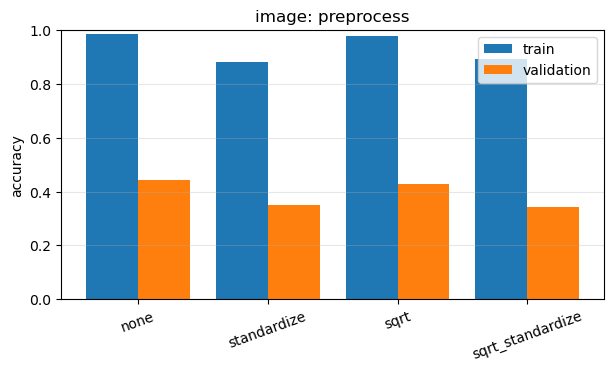

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,image,preprocess,none,0.9834,0.4433,0.5402,54,275.1
1,image,preprocess,standardize,0.8820,0.3510,0.5310,37,239.3
2,image,preprocess,sqrt,0.9757,0.4283,0.5474,47,293.8
3,image,preprocess,sqrt_standardize,0.8934,0.3440,0.5494,36,226.0


In [18]:
# Preprocessing
run_experiment("image", X_image, y_image, 50, IMAGE_BASELINE,
               "preprocess", ["none", "standardize", "sqrt", "sqrt_standardize"])

hidden_sizes = []               val 0.3067   train 0.4982   gap +0.191   best epoch  72   100.3s
hidden_sizes = [256]            val 0.3580   train 0.7011   gap +0.343   best epoch  49   139.4s
hidden_sizes = [1024]           val 0.4283   train 0.9757   gap +0.547   best epoch  47   261.3s
hidden_sizes = [1024, 256]      val 0.2977   train 0.5589   gap +0.261   best epoch  20   190.4s
hidden_sizes = [512, 256, 128]  val 0.1992   train 0.2569   gap +0.058   best epoch  14   126.8s


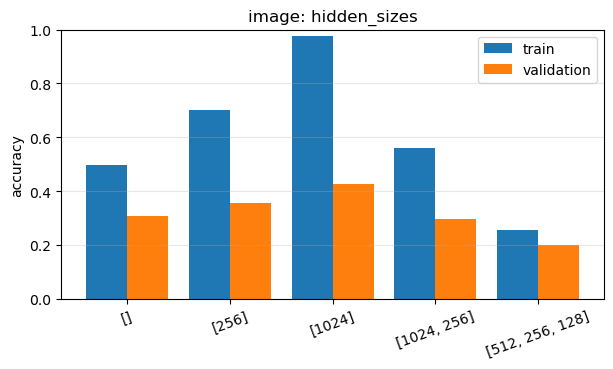

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,image,hidden_sizes,[],0.4982,0.3067,0.1914,72,100.3
1,image,hidden_sizes,[256],0.7011,0.3580,0.3431,49,139.4
2,image,hidden_sizes,[1024],0.9757,0.4283,0.5474,47,261.3
3,image,hidden_sizes,"[1024, 256]",0.5589,0.2977,0.2611,20,190.4
4,image,hidden_sizes,"[512, 256, 128]",0.2569,0.1992,0.0576,14,126.8


In [19]:
# Number of hidden layers and their size
run_experiment("image", X_image, y_image, 50, IMAGE_BASELINE,
               "hidden_sizes", [[], [256], [1024], [1024, 256], [512, 256, 128]])

activation = relu             val 0.4283   train 0.9757   gap +0.547   best epoch  47   249.2s
activation = tanh             val 0.2882   train 0.4621   gap +0.174   best epoch  17   159.1s
activation = sigmoid          val 0.3873   train 0.7205   gap +0.333   best epoch  99   321.8s


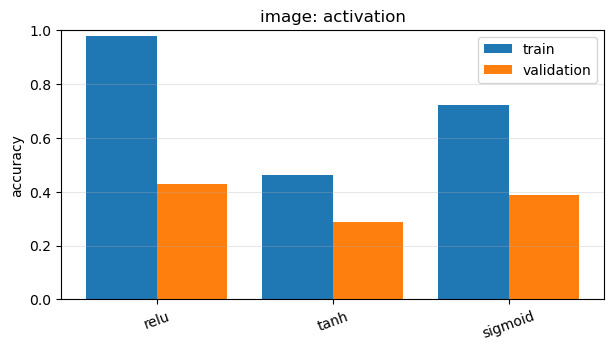

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,image,activation,relu,0.9757,0.4283,0.5474,47,249.2
1,image,activation,tanh,0.4621,0.2882,0.1738,17,159.1
2,image,activation,sigmoid,0.7205,0.3873,0.3332,99,321.8


In [20]:
# Activation function
run_experiment("image", X_image, y_image, 50, IMAGE_BASELINE,
               "activation", ["relu", "tanh", "sigmoid"])

dropout = 0.0              val 0.4560   train 0.9996   gap +0.544   best epoch  43   60.5s
dropout = 0.2              val 0.4440   train 0.9936   gap +0.550   best epoch  33   53.7s
dropout = 0.5              val 0.4283   train 0.9757   gap +0.547   best epoch  47   72.2s
dropout = 0.7              val 0.3945   train 0.8599   gap +0.465   best epoch  44   69.1s


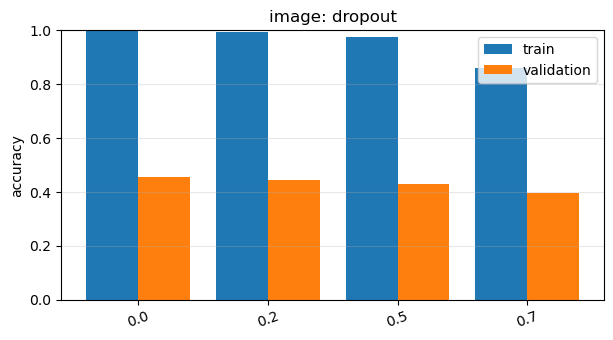

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,image,dropout,0.0,0.9996,0.4560,0.5436,43,60.5
1,image,dropout,0.2,0.9936,0.4440,0.5496,33,53.7
2,image,dropout,0.5,0.9757,0.4283,0.5474,47,72.2
3,image,dropout,0.7,0.8599,0.3945,0.4654,44,69.1


In [21]:
# Dropout (inside the network)
run_experiment("image", X_image, y_image, 50, IMAGE_BASELINE,
               "dropout", [0.0, 0.2, 0.5, 0.7])

input_dropout = 0.0              val 0.3850   train 1.0000   gap +0.615   best epoch  51   76.1s
input_dropout = 0.2              val 0.4353   train 1.0000   gap +0.565   best epoch  51   78.4s
input_dropout = 0.5              val 0.4283   train 0.9757   gap +0.547   best epoch  47   73.1s
input_dropout = 0.7              val 0.3155   train 0.5824   gap +0.267   best epoch  16   31.8s


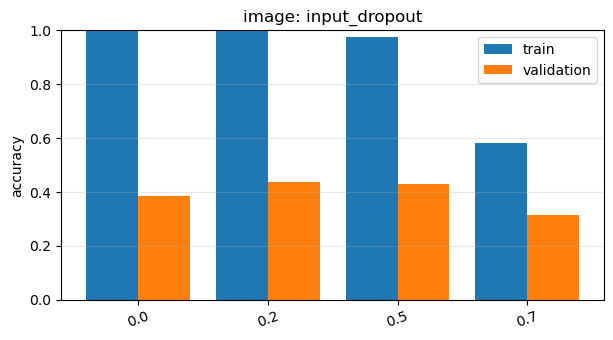

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,image,input_dropout,0.0,1.0000,0.3850,0.6150,51,76.1
1,image,input_dropout,0.2,1.0000,0.4353,0.5647,51,78.4
2,image,input_dropout,0.5,0.9757,0.4283,0.5474,47,73.1
3,image,input_dropout,0.7,0.5824,0.3155,0.2669,16,31.8


In [22]:
# Input dropout (on the features)
run_experiment("image", X_image, y_image, 50, IMAGE_BASELINE,
               "input_dropout", [0.0, 0.2, 0.5, 0.7])

lr = 0.01             val 0.2950   train 0.5882   gap +0.293   best epoch   7   24.8s
lr = 0.003            val 0.4283   train 0.9757   gap +0.547   best epoch  47   72.0s
lr = 0.001            val 0.4460   train 0.9676   gap +0.522   best epoch 100   125.7s
lr = 0.0001           val 0.2970   train 0.4301   gap +0.133   best epoch  96   126.4s


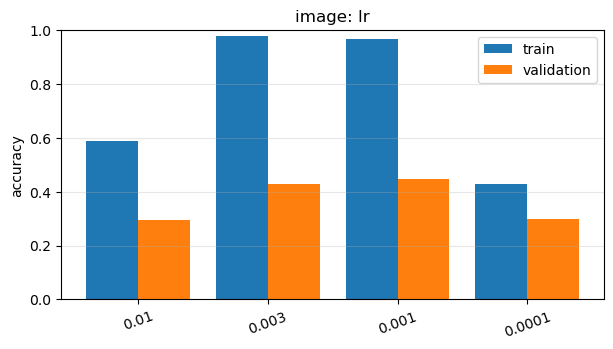

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,image,lr,0.01,0.5882,0.2950,0.2932,7,24.8
1,image,lr,0.003,0.9757,0.4283,0.5474,47,72.0
2,image,lr,0.001,0.9676,0.4460,0.5216,100,125.7
3,image,lr,0.0001,0.4301,0.2970,0.1331,96,126.4


In [23]:
# Learning rate
run_experiment("image", X_image, y_image, 50, IMAGE_BASELINE,
               "lr", [1e-2, 3e-3, 1e-3, 1e-4])

weight_decay = 0.0              val 0.4212   train 0.9754   gap +0.554   best epoch  45   69.1s
weight_decay = 0.001            val 0.4193   train 0.9601   gap +0.541   best epoch  36   58.4s
weight_decay = 0.01             val 0.4283   train 0.9757   gap +0.547   best epoch  47   73.1s
weight_decay = 0.1              val 0.4205   train 0.8966   gap +0.476   best epoch  50   77.7s


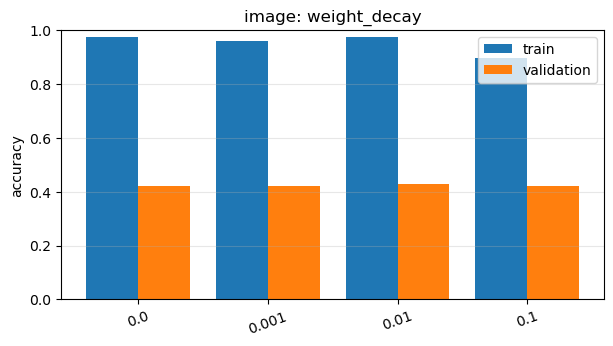

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,image,weight_decay,0.0,0.9754,0.4212,0.5541,45,69.1
1,image,weight_decay,0.001,0.9601,0.4193,0.5408,36,58.4
2,image,weight_decay,0.01,0.9757,0.4283,0.5474,47,73.1
3,image,weight_decay,0.1,0.8966,0.4205,0.4761,50,77.7


In [24]:
# Weight decay
run_experiment("image", X_image, y_image, 50, IMAGE_BASELINE,
               "weight_decay", [0.0, 1e-3, 1e-2, 1e-1])

batch_size = 32               val 0.3755   train 0.9004   gap +0.525   best epoch  24   104.7s
batch_size = 128              val 0.4283   train 0.9757   gap +0.547   best epoch  47   72.2s
batch_size = 512              val 0.4433   train 0.9743   gap +0.531   best epoch  74   61.1s


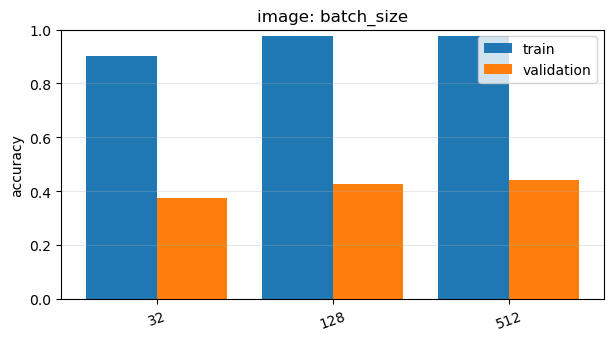

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,image,batch_size,32,0.9004,0.3755,0.5249,24,104.7
1,image,batch_size,128,0.9757,0.4283,0.5474,47,72.2
2,image,batch_size,512,0.9743,0.4433,0.5311,74,61.1


In [25]:
# Batch size
run_experiment("image", X_image, y_image, 50, IMAGE_BASELINE,
               "batch_size", [32, 128, 512])

Adam (baseline):
optimizer = adam             val 0.4283   train 0.9757   gap +0.547   best epoch  47   73.8s


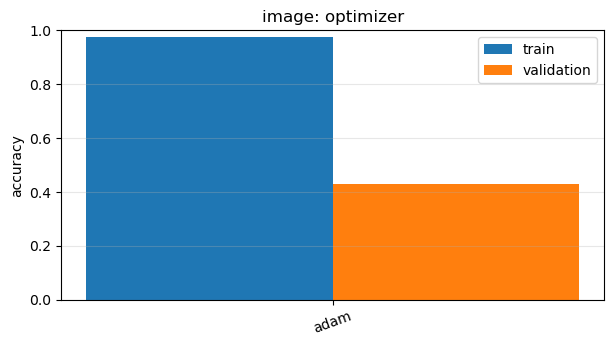

SGD with momentum:
optimizer = sgd              val 0.0932   train 0.1198   gap +0.027   best epoch  10   20.9s


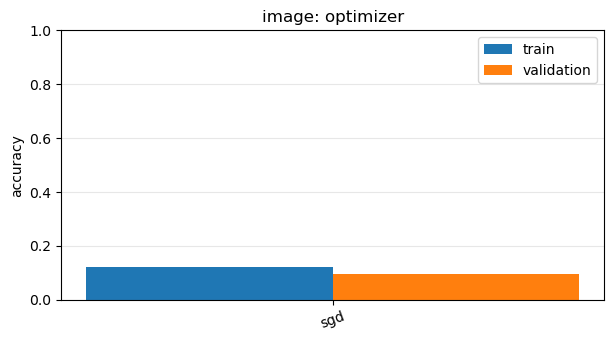

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,image,optimizer,sgd,0.1198,0.0932,0.0266,10,20.9


In [26]:
# Optimizer
sgd_settings = dict(IMAGE_BASELINE)
sgd_settings["lr"] = 1e-2
print("Adam (baseline):")
run_experiment("image", X_image, y_image, 50, IMAGE_BASELINE, "optimizer", ["adam"])
print("SGD with momentum:")
run_experiment("image", X_image, y_image, 50, sgd_settings, "optimizer", ["sgd"])

In [27]:
image_table = pd.DataFrame([r for r in all_results if r["task"] == "image"])
image_table.to_csv("results/nn/image_experiments.csv", index=False)
image_table

,task,hyperparameter,value,train_acc,val_acc,gap,best_epoch,seconds
0,image,preprocess,none,0.9834,0.4433,0.5402,54,275.1
1,image,preprocess,standardize,0.8820,0.3510,0.5310,37,239.3
2,image,preprocess,sqrt,0.9757,0.4283,0.5474,47,293.8
3,image,preprocess,sqrt_standardize,0.8934,0.3440,0.5494,36,226.0
4,image,hidden_sizes,[],0.4982,0.3067,0.1914,72,100.3
5,image,hidden_sizes,[256],0.7011,0.3580,0.3431,49,139.4
6,image,hidden_sizes,[1024],0.9757,0.4283,0.5474,47,261.3
7,image,hidden_sizes,"[1024, 256]",0.5589,0.2977,0.2611,20,190.4
8,image,hidden_sizes,"[512, 256, 128]",0.2569,0.1992,0.0576,14,126.8
9,image,activation,relu,0.9757,0.4283,0.5474,47,249.2


## 7. Best models

**After looking at the tables above**, write the best value of each hyperparameter into `BEST_SENTIMENT` and `BEST_IMAGE` (they start as copies of the baselines).

Then we:

1. train each best model with **3 different seeds** to see how stable the result is (mean ± std),
2. look at the **confusion matrix** and per-class results (error analysis).

In [28]:
BEST_SENTIMENT = dict(SENTIMENT_BASELINE)   # e.g. BEST_SENTIMENT["dropout"] = 0.5
BEST_IMAGE = dict(IMAGE_BASELINE)


def evaluate_best(task, X, y, n_classes, settings, seeds=[42, 1, 2]):
    X_tr, y_tr, X_va, y_va = prepare(X, y, settings["preprocess"])
    accuracies = []
    best_epochs = []
    for seed in seeds:
        model, history = train(X_tr, y_tr, X_va, y_va, n_classes, settings, seed=seed)
        acc = history["val_acc"][history["best_epoch"] - 1]
        accuracies.append(acc)
        best_epochs.append(history["best_epoch"])
        print(f"seed {seed}: validation accuracy {acc:.4f} (best epoch {history['best_epoch']})")
        if seed == seeds[0]:
            first_model = model
            first_history = history

    print(f"{task}: {np.mean(accuracies):.4f} ± {np.std(accuracies):.4f}")
    plot_history(first_history, f"{task} – best model")

    # predictions of the first model on the validation set
    first_model.eval()
    with torch.no_grad():
        y_pred = first_model(torch.tensor(X_va).to(device)).argmax(dim=1).cpu().numpy()
    cm = common.confusion_matrix(y_va, y_pred, n_classes)
    return cm, int(round(np.mean(best_epochs)))


def plot_confusion(cm, title, labels=None):
    normalized = cm / cm.sum(axis=1, keepdims=True)   # each row sums to 1
    size = 5 if len(cm) <= 3 else 10
    plt.figure(figsize=(size, size * 0.85))
    plt.imshow(normalized, cmap="Blues", vmin=0, vmax=1)
    plt.colorbar()
    if labels is not None:
        plt.xticks(range(len(labels)), labels)
        plt.yticks(range(len(labels)), labels)
        for i in range(len(cm)):
            for j in range(len(cm)):
                color = "white" if normalized[i, j] > 0.5 else "black"
                plt.text(j, i, f"{cm[i, j]}\n{normalized[i, j]:.0%}",
                         ha="center", va="center", color=color)
    plt.xlabel("predicted class")
    plt.ylabel("true class")
    plt.title(title)
    plt.show()

### 7.1 Sentiment

seed 42: validation accuracy 0.6808 (best epoch 27)
seed 1: validation accuracy 0.6771 (best epoch 19)
seed 2: validation accuracy 0.6792 (best epoch 18)
sentiment: 0.6790 ± 0.0015


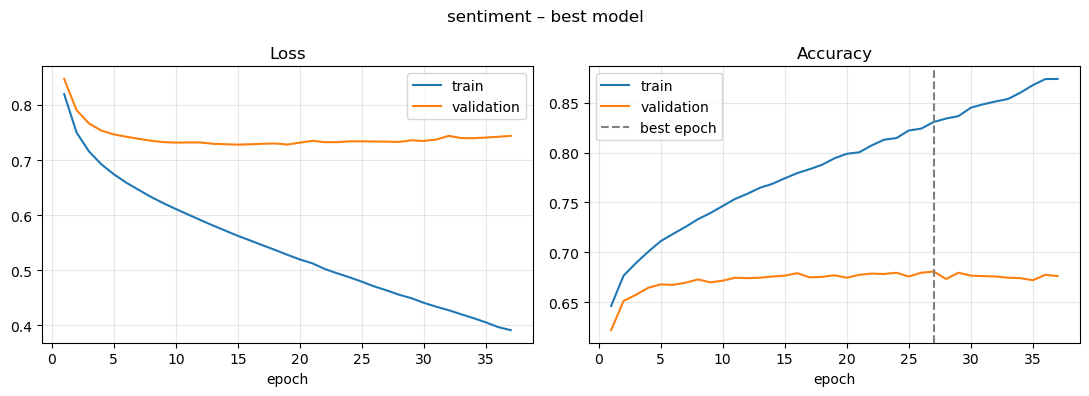

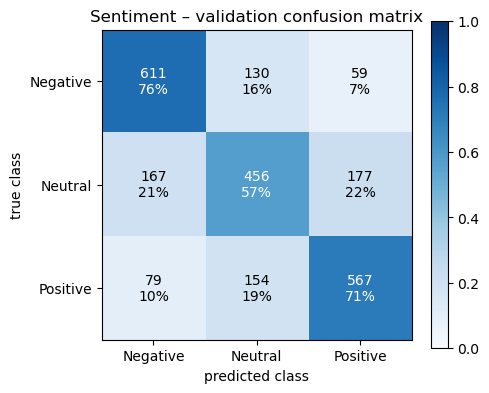

Negative  recall 0.764   precision 0.713
Neutral   recall 0.570   precision 0.616
Positive  recall 0.709   precision 0.706


In [29]:
cm_sent, best_epochs_sent = evaluate_best("sentiment", X_sent, y_sent, 3, BEST_SENTIMENT)
plot_confusion(cm_sent, "Sentiment – validation confusion matrix", common.SENTIMENT_NAMES)

recall = common.per_class_recall(cm_sent)
precision = common.per_class_precision(cm_sent)
for i, name in enumerate(common.SENTIMENT_NAMES):
    print(f"{name:<9} recall {recall[i]:.3f}   precision {precision[i]:.3f}")

*Question for the report: is Neutral harder than Negative and Positive? Into which class do the Neutral mistakes go?*

### 7.2 Image

seed 42: validation accuracy 0.4283 (best epoch 47)
seed 1: validation accuracy 0.4305 (best epoch 53)
seed 2: validation accuracy 0.4358 (best epoch 47)
image: 0.4315 ± 0.0031


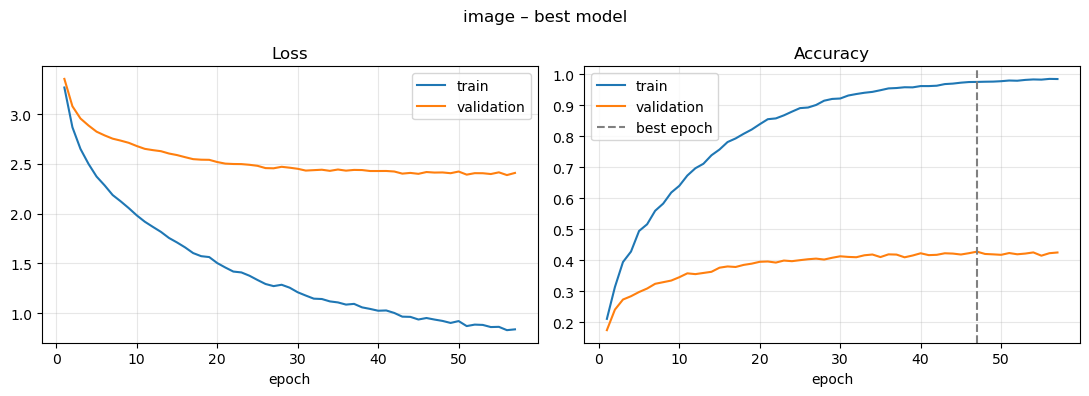

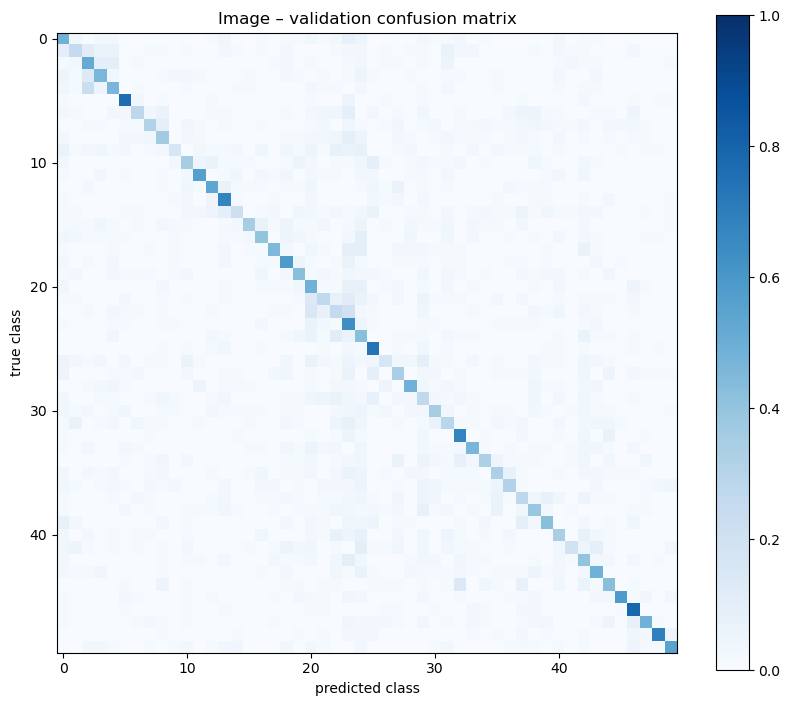

5 hardest classes: [(26, 0.16), (9, 0.16), (41, 0.19), (14, 0.21), (1, 0.25)]
5 easiest classes: [(32, 0.68), (48, 0.69), (25, 0.74), (5, 0.76), (46, 0.79)]

Most frequent mistakes (true class, predicted class, count):
   4 ->  2   18 times
  22 -> 23   16 times
  22 -> 20   12 times
  44 -> 32   11 times
   3 ->  2   10 times
  21 -> 20   10 times
   1 ->  2   9 times
  21 -> 23   9 times
  24 -> 22   9 times
   1 ->  0   8 times


In [30]:
cm_image, best_epochs_image = evaluate_best("image", X_image, y_image, 50, BEST_IMAGE)
plot_confusion(cm_image, "Image – validation confusion matrix")

recall = common.per_class_recall(cm_image)
order = np.argsort(recall)          # classes sorted from worst to best recall
print("5 hardest classes:", [(int(c), round(float(recall[c]), 2)) for c in order[:5]])
print("5 easiest classes:", [(int(c), round(float(recall[c]), 2)) for c in order[-5:]])
print("\nMost frequent mistakes (true class, predicted class, count):")
for true_c, pred_c, count in common.most_confused_pairs(cm_image, 10):
    print(f"  {true_c:2d} -> {pred_c:2d}   {count} times")

## 8. Final models and Kaggle file

Now we train the best models on **all** the training data (train + validation). There is no validation set anymore, so early stopping cannot be used. Instead we train for a fixed number of epochs: the average best epoch from section 7, times 1.25 because there is 25% more data.

The predictions of each task are also saved separately (`predictions/nn_image_test.csv`, `predictions/nn_sentiment_test.csv`), so the team can combine the best model of each task later (for example k-NN for images and the NN for sentiment).

In [31]:
def train_on_all_data(X, y, X_test, n_classes, settings, n_epochs, seed=42):
    s = dict(DEFAULT_SETTINGS)
    s.update(settings)
    common.set_seed(seed)

    stats = common.fit_preprocessing(X, s["preprocess"])          # all training rows
    X_all = torch.tensor(common.apply_preprocessing(X, s["preprocess"], stats)).to(device)
    y_all = torch.tensor(y).to(device)
    X_test = torch.tensor(common.apply_preprocessing(X_test, s["preprocess"], stats)).to(device)

    model = MLP(X_all.shape[1], n_classes, s["hidden_sizes"], s["activation"],
                s["dropout"], s["input_dropout"]).to(device)
    loss_function = nn.CrossEntropyLoss()
    if s["optimizer"] == "adam":
        optimizer = torch.optim.AdamW(model.parameters(), lr=s["lr"], weight_decay=s["weight_decay"])
    else:
        optimizer = torch.optim.SGD(model.parameters(), lr=s["lr"], momentum=0.9,
                                    weight_decay=s["weight_decay"])

    for epoch in range(n_epochs):
        model.train()
        order = torch.randperm(len(X_all), device=device)
        for start in range(0, len(X_all), s["batch_size"]):
            batch = order[start:start + s["batch_size"]]
            loss = loss_function(model(X_all[batch]), y_all[batch])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        test_predictions = model(X_test).argmax(dim=1).cpu().numpy()
    return test_predictions


epochs_sent = int(round(best_epochs_sent * 1.25))
epochs_image = int(round(best_epochs_image * 1.25))
print("sentiment epochs:", epochs_sent, "| image epochs:", epochs_image)

sent_pred = train_on_all_data(X_sent, y_sent, X_sent_test, 3, BEST_SENTIMENT, epochs_sent)
image_pred = train_on_all_data(X_image, y_image, X_image_test, 50, BEST_IMAGE, epochs_image)

print("predicted sentiment classes:", np.bincount(sent_pred, minlength=3))
print("predicted image classes (first 10):", np.bincount(image_pred, minlength=50)[:10])

sentiment epochs: 26 | image epochs: 61
predicted sentiment classes: [2309 1331 1360]
predicted image classes (first 10): [190  71 129  67 156  90  53  98  88  42]


In [32]:
# Save each task separately, then the combined Kaggle file
pd.DataFrame({"id": sent_test_ids, "label": sent_pred}).to_csv("predictions/nn_sentiment_test.csv", index=False)
pd.DataFrame({"id": image_test_ids, "label": image_pred}).to_csv("predictions/nn_image_test.csv", index=False)

submission = common.make_submission(image_test_ids, image_pred, sent_test_ids, sent_pred,
                                    "predictions/submission_nn.csv")
print(len(submission), "rows written to predictions/submission_nn.csv")
submission.head()

10000 rows written to predictions/submission_nn.csv


,id,label
0,text_003234,2
1,text_004517,2
2,img_000140,39
3,img_004880,16
4,text_002494,0
